In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [ ]:

# Load your uploaded CSV file
df = pd.read_csv("/content/house_price_dataset.csv")

# Preview dataset
print("First 5 rows:")
print(df.head())

print("\nDataset Info:")
print(df.info())

print("\nStatistical Summary:")
print(df.describe())


First 5 rows:
                  date      price  bedrooms  bathrooms  sqft_living  sqft_lot  \
0  2014-05-02 00:00:00   313000.0       3.0       1.50         1340      7912   
1  2014-05-02 00:00:00  2384000.0       5.0       2.50         3650      9050   
2  2014-05-02 00:00:00   342000.0       3.0       2.00         1930     11947   
3  2014-05-02 00:00:00   420000.0       3.0       2.25         2000      8030   
4  2014-05-02 00:00:00   550000.0       4.0       2.50         1940     10500   

   floors  waterfront  view  condition  sqft_above  sqft_basement  yr_built  \
0     1.5           0     0          3        1340              0      1955   
1     2.0           0     4          5        3370            280      1921   
2     1.0           0     0          4        1930              0      1966   
3     1.0           0     0          4        1000           1000      1963   
4     1.0           0     0          4        1140            800      1976   

   yr_renovated         

In [ ]:
print("\nMissing Values:")
print(df.isnull().sum())



Missing Values:
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
street           0
city             0
statezip         0
country          0
dtype: int64


In [ ]:
# Drop missing values
df = df.dropna()

# df.fillna(df.mean(), inplace=True)

print("\nAfter Cleaning Missing Values:")
print(df.isnull().sum())



After Cleaning Missing Values:
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
street           0
city             0
statezip         0
country          0
dtype: int64


In [ ]:
print("\nDuplicate Rows:", df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicates after removal:", df.duplicated().sum())



Duplicate Rows: 0
Duplicates after removal: 0


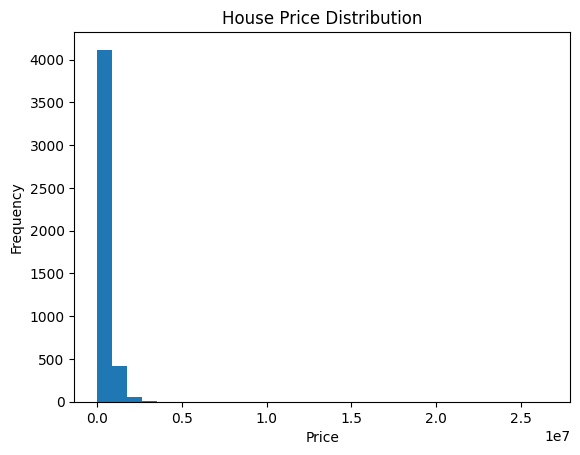

In [ ]:
plt.hist(df["price"], bins=30)
plt.title("House Price Distribution")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()


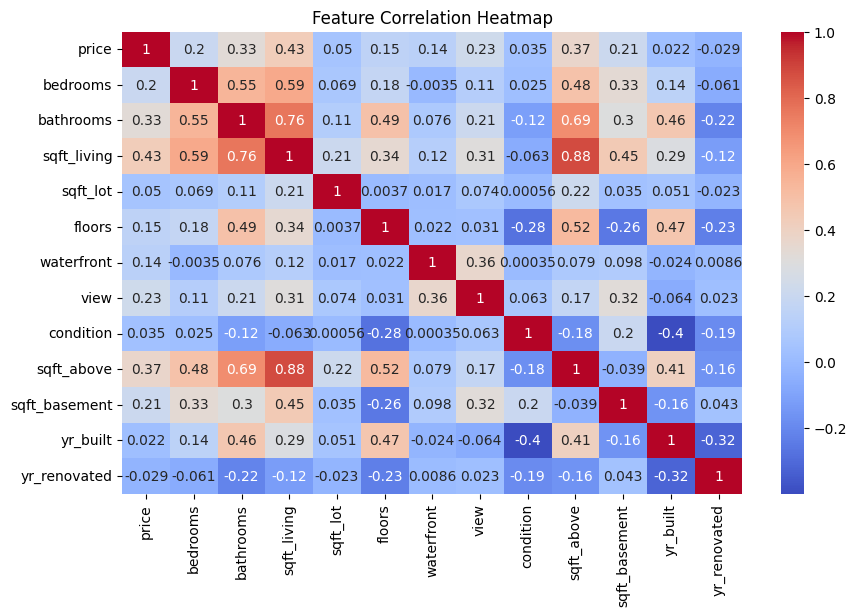

In [ ]:
plt.figure(figsize=(10, 6))

numeric_df = df.select_dtypes(include=[np.number])

sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm")

plt.title("Feature Correlation Heatmap")
plt.show()


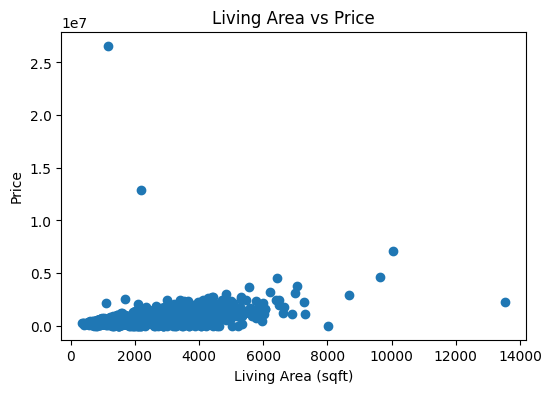

In [ ]:
plt.figure(figsize=(6, 4))

plt.scatter(df["sqft_living"], df["price"])

plt.xlabel("Living Area (sqft)")
plt.ylabel("Price")
plt.title("Living Area vs Price")

plt.show()


In [ ]:
# Separate features and target
X = df.drop("price", axis=1)
y = df["price"]

print("\nFeature Columns:")
print(X.columns)

print("\nFeatures Preview:")
print(X.head())

print("\nTarget Preview:")
print(y.head())



Feature Columns:
Index(['date', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors',
       'waterfront', 'view', 'condition', 'sqft_above', 'sqft_basement',
       'yr_built', 'yr_renovated', 'street', 'city', 'statezip', 'country'],
      dtype='object')

Features Preview:
                  date  bedrooms  bathrooms  sqft_living  sqft_lot  floors  \
0  2014-05-02 00:00:00       3.0       1.50         1340      7912     1.5   
1  2014-05-02 00:00:00       5.0       2.50         3650      9050     2.0   
2  2014-05-02 00:00:00       3.0       2.00         1930     11947     1.0   
3  2014-05-02 00:00:00       3.0       2.25         2000      8030     1.0   
4  2014-05-02 00:00:00       4.0       2.50         1940     10500     1.0   

   waterfront  view  condition  sqft_above  sqft_basement  yr_built  \
0           0     0          3        1340              0      1955   
1           0     4          5        3370            280      1921   
2           0     0          4  

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)



Training Data Shape: (3680, 17)
Testing Data Shape: (920, 17)


In [ ]:
df_model = df.select_dtypes(include=["int64", "float64"])

print("Numeric columns:")
print(df_model.columns)


Numeric columns:
Index(['price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors',
       'waterfront', 'view', 'condition', 'sqft_above', 'sqft_basement',
       'yr_built', 'yr_renovated'],
      dtype='object')


In [ ]:
X = df_model.drop("price", axis=1)
y = df_model["price"]

print("\n Features shape:", X.shape)
print(" Target shape:", y.shape)



 Features shape: (4600, 12)
 Target shape: (4600,)


In [ ]:


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print("\n Data split completed")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)



 Data split completed
X_train: (3680, 12)
X_test: (920, 12)


In [ ]:


model = LinearRegression()
model.fit(X_train, y_train)

print("\n Model Training Completed")



 Model Training Completed


In [ ]:
y_pred = model.predict(X_test)

print("\n Predictions:")
print(y_pred[:5])



 Predictions:
[ 304863.38578076  326517.06991516 1071762.53630098  546241.40097359
  379799.98321087]


In [ ]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\n Model Performance Metrics:")
print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R² Score:", r2)


# MAE → Average error
# MSE → Squared error
# RMSE → Error in original units
# R² → Goodness of fit




 Model Performance Metrics:
MAE : 210908.17325009225
MSE : 986921767056.0986
RMSE: 993439.3625461488
R² Score: 0.032283856632802865


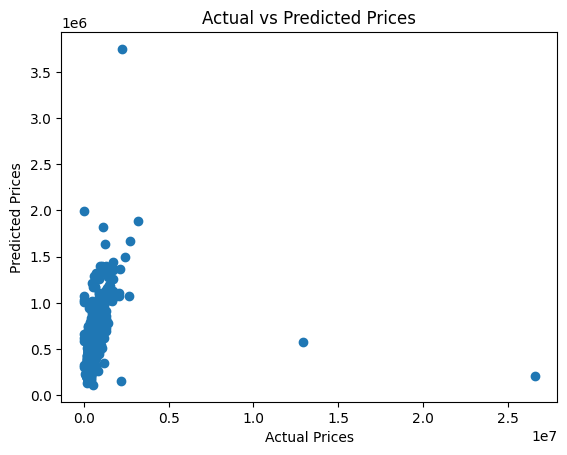

In [ ]:
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title("Actual vs Predicted Prices")
plt.show()
